# ABATA AI — LightGBM Quantile Regression & Newsvendor
**Notebook canonical — mode demo sintetis.**

Jalankan cell berurutan (CPU cukup). Upload `ABATA_seed_v2.zip` saat diminta. Notebook ini menggunakan source Python yang sama persis dengan paket integrasi website. Prediksi `quantity` dan `demand_quantity` terpisah. Status `experimental_not_approved`. Hasil 30 hari historis adalah evaluasi ulang eksploratif; bukan test independen baru.

**Alur:** validasi → EDA → fitur kausal → CV kronologis → kalibrasi residual → evaluasi → ekspor model → prediksi H+1 → restock → backtest.

Mode lokal opsional: `ABATA_SEED_DIR` menunjuk folder dataset; `ABATA_SKIP_INSTALL=1` hanya jika dependency sudah cocok. Tidak ada akses DB.

## 1. Dependency dan direktori kerja

In [1]:
import os, sys, subprocess, importlib.metadata as im
from pathlib import Path
requirements = ['lightgbm==4.6.0','pandas==2.2.3','numpy==2.3.5','scikit-learn==1.8.0','joblib==1.5.3']
if os.getenv('ABATA_SKIP_INSTALL') != '1':
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*requirements])
for req in requirements:
    name,version=req.split('=='); actual=im.version(name); print(name,actual)
    if actual!=version: raise RuntimeError(f'{name}: expected {version}, got {actual}. Restart runtime if necessary.')
WORK=Path.cwd()/'abata_colab_work'; WORK.mkdir(exist_ok=True)
OUT=WORK/'model_run'; OUT.mkdir(exist_ok=True)

lightgbm 4.6.0
pandas 2.2.3
numpy 2.3.5
scikit-learn 1.8.0
joblib 1.5.3


## 2. Upload dataset asli V2
Pada Colab pilih ZIP dataset yang sudah diberikan, bukan notebook lama atau CSV legacy.

In [2]:
import zipfile, io
if os.getenv('ABATA_SEED_DIR'):
    SEED=Path(os.environ['ABATA_SEED_DIR']).resolve()
else:
    from google.colab import files
    uploaded=files.upload()
    candidates=[(k,v) for k,v in uploaded.items() if k.lower().endswith('.zip')]
    if len(candidates)!=1: raise ValueError('Upload tepat satu ABATA_seed_v2.zip')
    dest=WORK/'seed'; dest.mkdir(exist_ok=True)
    required={'dataset_abata_v2.csv','product_master.csv','calendar.csv','menu_sales.csv','recipes_bom.csv'}
    with zipfile.ZipFile(io.BytesIO(candidates[0][1])) as z:
        found={}
        for info in z.infolist():
            name=Path(info.filename).name
            if name in required:
                if name in found or info.file_size>10_000_000: raise ValueError('ZIP invalid')
                found[name]=info
        if set(found)!=required: raise ValueError('File dataset tidak lengkap')
        for name,info in found.items(): (dest/name).write_bytes(z.read(info))
    SEED=dest
H=SEED/'dataset_abata_v2.csv'; M=SEED/'product_master.csv'
print(SEED)

Saving ABATA_seed_v2 (1).zip to ABATA_seed_v2 (1).zip
/content/abata_colab_work/seed


## 3. Source canonical ML
Cell ini menuliskan source integrasi yang sama persis; jangan mengedit rumus di notebook saja.

In [3]:
%%writefile abata_colab_work/abata_ml.py
"""Canonical ABATA demo training and load-only inference. No database access."""
import argparse, hashlib, json, math, sys
from pathlib import Path
from statistics import NormalDist
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib, sklearn
SCOPE='synthetic_seed_v2'; STATUS='experimental_not_approved'; TARGETS=['quantity','demand_quantity']; CAL=60
FLAGS=['is_holiday','is_promotion','is_ramadan','is_eid_period']
F1=['day_of_week','day_of_month','month','is_weekend','is_payday']+[f'lag_{i}' for i in range(1,8)]+['rolling_mean_7','rolling_std_7']
F2=F1+[f'lag_{i}' for i in [14,21,28]]+[f'rolling_{s}_{w}' for w in [14,28] for s in ['mean','std']]+['trend_day']
SETS={'F1':F1,'F2':F2,'F3':F2+FLAGS}
CONFIGS=[dict(n_estimators=100,learning_rate=.05,num_leaves=7,min_child_samples=20,reg_lambda=1.),dict(n_estimators=160,learning_rate=.04,num_leaves=15,min_child_samples=30,reg_lambda=3.)]
def sha(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def save(p,x): Path(p).write_text(json.dumps(x,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
def master_read(p):
    m=pd.read_csv(p).set_index('product_name').sort_index(); c=['purchase_cost','underage_cost','overage_cost','order_multiple','lead_time','shelf_life_days']
    if len(m)!=4 or not m.index.is_unique or not m.data_source.eq(SCOPE).all(): raise ValueError('Invalid demo master')
    m[c]=m[c].apply(pd.to_numeric,errors='raise')
    if not np.isfinite(m[c]).all().all() or (m[c]<=0).any().any() or not m.lead_time.eq(1).all(): raise ValueError('Invalid cost/multiple or unsupported lead time')
    m['cf']=m.underage_cost/(m.underage_cost+m.overage_cost); return m
def history_read(p,m):
    d=pd.read_csv(p); cols=['date','product_name','unit','data_source',*TARGETS,*FLAGS]
    if not set(cols)<=set(d) or d[cols].isna().any().any() or not d.data_source.eq(SCOPE).all(): raise ValueError('Missing fields or mixed scope')
    d.date=pd.to_datetime(d.date,format='%Y-%m-%d',errors='raise'); d=d.sort_values(['product_name','date']).reset_index(drop=True)
    if d.duplicated(['product_name','date']).any() or set(d.product_name)!=set(m.index): raise ValueError('Duplicate or unknown product')
    days=pd.date_range(d.date.min(),d.date.max())
    for p,g in d.groupby('product_name'):
        if not pd.DatetimeIndex(g.date).equals(days) or not g.unit.eq(m.loc[p,'unit']).all(): raise ValueError('Incomplete dates or unit mismatch: '+p)
    for c in TARGETS+FLAGS: d[c]=pd.to_numeric(d[c],errors='raise')
    if not np.isfinite(d[TARGETS+FLAGS]).all().all() or (d[TARGETS]<0).any().any() or (d.quantity>d.demand_quantity+1e-8).any() or not d[FLAGS].isin([0,1]).all().all() or (d.groupby('date')[FLAGS].nunique()>1).any().any(): raise ValueError('Invalid target/calendar')
    return d
def validate_seed(folder):
    p=Path(folder); m=master_read(p/'product_master.csv'); d=history_read(p/'dataset_abata_v2.csv',m); s=pd.read_csv(p/'menu_sales.csv'); b=pd.read_csv(p/'recipes_bom.csv'); c=pd.read_csv(p/'calendar.csv')
    if any(not x.data_source.eq(SCOPE).all() for x in [s,b,c]) or s.duplicated(['date','menu_id']).any() or b.duplicated(['menu_id','product_name']).any() or c.date.duplicated().any(): raise ValueError('Invalid seed keys/scope')
    if not (s.requested_qty==s.sold_qty+s.lost_qty).all() or not b.unit.eq(b.product_name.map(m.unit)).all(): raise ValueError('Invalid BOM/menu')
    j=s.merge(b,on='menu_id'); j.date=pd.to_datetime(j.date); j['u']=j.sold_qty*j.quantity_per_menu; j['d']=j.requested_qty*j.quantity_per_menu
    z=d.set_index(['date','product_name']).join(j.groupby(['date','product_name'])[['u','d']].sum(),how='outer'); diff=max((z.u-z.quantity).abs().max(),(z.d-z.demand_quantity).abs().max()); bal=(d.opening_stock+d.incoming_stock-d.quantity-d.waste_quantity-d.closing_stock).abs().max(); continuity=(d.opening_stock-d.groupby('product_name').closing_stock.shift()).abs().max()
    c.date=pd.to_datetime(c.date); zc=d.merge(c[['date']+FLAGS],on='date',suffixes=('','_cal'),validate='many_to_one')
    if z[['u','d','quantity','demand_quantity']].isna().any().any() or max(diff,bal,continuity)>.002 or len(zc)!=len(d) or any(not zc[f].eq(zc[f+'_cal']).all() for f in FLAGS): raise ValueError('Seed reconciliation failed')
    return dict(rows=len(d),days=int(d.date.nunique()),products=len(m),bom_rows=len(b),menu_rows=len(s),max_bom_error=float(diff),max_stock_error=float(bal),max_continuity_error=float(continuity),sha256={n:sha(p/n) for n in ['dataset_abata_v2.csv','product_master.csv','calendar.csv','menu_sales.csv','recipes_bom.csv']})
def features(g,t,origin):
    f=g.copy().sort_values('date'); dt=f.date.dt; f['day_of_week']=(dt.dayofweek+1)%7+1; f['day_of_month']=dt.day; f['month']=dt.month; f['is_weekend']=(dt.dayofweek>=5).astype(int); f['is_payday']=((dt.day>=25)|(dt.day<=3)).astype(int); f['trend_day']=(f.date-origin).dt.days
    for i in [1,2,3,4,5,6,7,14,21,28]: f[f'lag_{i}']=f[t].shift(i)
    for w in [7,14,28]:
        r=f[t].shift().rolling(w); f[f'rolling_mean_{w}']=r.mean(); f[f'rolling_std_{w}']=r.std(ddof=1)
    return f
def fit(f,cols,t,a,params): return lgb.LGBMRegressor(objective='quantile',alpha=a,random_state=42,n_jobs=1,verbosity=-1,deterministic=True,force_col_wise=True,**params).fit(f[cols],f[t])
def pin(y,p,a):
    e=np.asarray(y)-np.asarray(p); return float(np.maximum(a*e,(a-1)*e).mean())
def metrics(y,p,a):
    y=np.asarray(y,float); p=np.asarray(p,float); e=y-p; return dict(n=len(y),mae=float(abs(e).mean()),rmse=float(np.sqrt(np.mean(e**2))),wape=float(abs(e).sum()/abs(y).sum()) if abs(y).sum() else None,pinball=pin(y,p,a),coverage=float(np.mean(y<=p)))
def correction(r,a):
    x=np.sort(np.asarray(r)[-CAL:]); return float(x[min(len(x),max(1,math.ceil((len(x)+1)*a)))-1])
def monotone(x): return np.maximum.accumulate(np.maximum(0,x))
def qdefs(t,cf): return sorted([('q50',.5),('q80',.8)]+([('qcf',float(cf))] if t=='demand_quantity' else []),key=lambda z:z[1])
def prefix(d,cut):
    x=d.loc[d.date<=pd.Timestamp(cut),['date','product_name','unit','data_source',*TARGETS,*FLAGS]].copy(); x.date=x.date.dt.strftime('%Y-%m-%d'); x[TARGETS]=x[TARGETS].astype(float); x[FLAGS]=x[FLAGS].astype(int); return hashlib.sha256(x.to_csv(index=False,float_format='%.8f').encode()).hexdigest()
def train(history,master,out,seed_folder=None):
    out=Path(out); (out/'models').mkdir(parents=True,exist_ok=True); m=master_read(master); d=history_read(history,m); days=pd.date_range(d.date.min(),d.date.max()); origin=days[0]; validation=validate_seed(seed_folder) if seed_folder else None
    if len(days)<300: raise ValueError('Requires >=300 complete days')
    ts=days[-30]; cs=days[-90]; ds=days[-60]; cv_ends=[cs-pd.Timedelta(days=1+30*k) for k in [2,1,0]]
    tune=[]; predictions=[]; residuals=[]; ev=[]; models=[]; run='abata-ml-'+hashlib.sha256((sha(history)+sha(master)+sha(__file__)).encode()).hexdigest()[:16]
    for product,g in d.groupby('product_name'):
        p=m.loc[product]
        for t in TARGETS:
            f=features(g,t,origin); dev=f[f.date<cs].iloc[28:]; ca=f[(f.date>=cs)&(f.date<ts)]; te=f[f.date>=ts]; qs=qdefs(t,p.cf); raw={}; corrected={}; sigma={}; baseline={}
            for q,a in qs:
                scores=[]
                for fs,cols in SETS.items():
                    for ci,params in enumerate(CONFIGS):
                        losses=[]
                        for end in cv_ends:
                            start=end-pd.Timedelta(days=29); tr=dev[dev.date<start]; va=dev[dev.date.between(start,end)]; model=fit(tr,cols,t,a,params); loss=pin(va[t],model.predict(va[cols]),a); losses.append(loss); tune.append(dict(run_id=run,product_name=product,target=t,quantile=q,alpha=a,feature_set=fs,config=ci,train_end=str(tr.date.max().date()),validation_start=str(start.date()),validation_end=str(end.date()),pinball=loss))
                        scores.append((np.mean(losses),fs,ci))
                score,fs,ci=min(scores); cols=SETS[fs]; params=CONFIGS[ci]; model=fit(dev,cols,t,a,params); cp=model.predict(ca[cols]); r=list(ca[t].to_numpy()-cp); raw[q]=model.predict(te[cols]); vals=[]; sig=[]
                for dt,y,rp in zip(ca.date,ca[t],cp): residuals.append(dict(run_id=run,product_name=product,target=t,quantile=q,alpha=a,date=str(dt.date()),actual=y,raw_prediction=rp,residual=y-rp,fit_end=str(dev.date.max().date())))
                for y,rp in zip(te[t],raw[q]): vals.append(rp+correction(r,a)); sig.append(float(np.std(r[-CAL:],ddof=1))); r.append(float(y-rp))
                corrected[q]=np.asarray(vals); sigma[q]=sig
                tr=f[f.date<ds].iloc[28:]; va=f[f.date>=ds]; model=fit(tr,cols,t,a,params); dr=va[t].to_numpy()-model.predict(va[cols]); name=f'{len(models):02d}_{t}_{q}'; txt=out/'models'/f'{name}.txt'; jb=out/'models'/f'{name}.joblib'; model.booster_.save_model(str(txt)); joblib.dump(model,jb,compress=3)
                models.append(dict(product_name=product,unit=p.unit,target=t,quantile=q,alpha=a,feature_set=fs,features=cols,parameters=params,cv_pinball=float(score),fit_end=str(tr.date.max().date()),calibration_start=str(ds.date()),calibration_end=str(days[-1].date()),initial_correction=correction(dr,a),initial_sigma=float(np.std(dr,ddof=1)),booster=str(txt.relative_to(out)),booster_sha256=sha(txt),joblib=str(jb.relative_to(out)),joblib_sha256=sha(jb)))
                baseline[q]=f[t].shift().rolling(28).quantile(a,interpolation='linear').iloc[-30:].to_numpy()
            final=np.array([monotone(x) for x in np.column_stack([corrected[q] for q,a in qs])]); y=te[t].to_numpy()
            for k,(q,a) in enumerate(qs):
                for i,dt in enumerate(te.date): predictions.append(dict(run_id=run,product_name=product,unit=p.unit,target=t,date=str(dt.date()),quantile=q,alpha=a,actual=float(y[i]),raw_prediction=float(raw[q][i]),calibrated_prediction=float(corrected[q][i]),prediction=float(final[i,k]),sigma_q50=sigma['q50'][i],empirical_prediction=float(baseline[q][i])))
                comps={'raw':raw[q],'calibrated':corrected[q],'final':final[:,k],'empirical28':baseline[q]}
                if q=='q50': comps.update(lag1=te.lag_1,lag7=te.lag_7,median7=f[t].shift().rolling(7).median().iloc[-30:])
                for v,pr in comps.items(): ev.append(dict(run_id=run,product_name=product,unit=p.unit,target=t,quantile=q,alpha=a,variant=v,**metrics(y,pr,a)))
            print('Trained',product,t,file=sys.stderr,flush=True)
    pred=pd.DataFrame(predictions); assert len(pred)==600 and not pred.duplicated(['product_name','target','date','quantile']).any()
    for n,x in [('test_predictions',pred),('evaluation',pd.DataFrame(ev)),('tuning',pd.DataFrame(tune)),('calibration_residuals',pd.DataFrame(residuals))]: x.to_csv(out/f'{n}.csv',index=False)
    man=dict(schema_version='abata-ml-3',run_id=run,status=STATUS,scope=SCOPE,history_sha256=sha(history),master_sha256=sha(master),pipeline_sha256=sha(__file__),history_start=str(origin.date()),history_end=str(days[-1].date()),deployment_fit_end=str(days[-61].date()),fit_prefix_sha256=prefix(d,days[-61]),historical_test_start=str(ts.date()),historical_test_end=str(days[-1].date()),evaluation_label='exploratory_historical_rolling_origin_not_independent',calibration='Rolling previous 60 raw residuals only; finite sample order statistic; cumulative max in alpha order',python=sys.version.split()[0],dependencies={'lightgbm':lgb.__version__,'pandas':pd.__version__,'numpy':np.__version__,'scikit-learn':sklearn.__version__,'joblib':joblib.__version__},seed_validation=validation,models=models); save(out/'manifest.json',man); return man
def predict(history,master,model_dir,forecast_date,calendar=None):
    md=Path(model_dir); man=json.loads((md/'manifest.json').read_text()); m=master_read(master); d=history_read(history,m); date=pd.Timestamp(forecast_date)
    if man['scope']!=SCOPE or man['status']!=STATUS or man['schema_version']!='abata-ml-3' or sha(master)!=man['master_sha256']: raise ValueError('Invalid manifest/master')
    if date!=d.date.max()+pd.Timedelta(days=1) or d.date.max()<pd.Timestamp(man['history_end']) or prefix(d,man['deployment_fit_end'])!=man['fit_prefix_sha256']: raise ValueError('Need complete H+1 history with unchanged fit prefix')
    flags={c:np.nan for c in FLAGS}
    if calendar:
        z=pd.read_csv(calendar)
        if len(z)!=1 or str(z.date.iloc[0])!=str(date.date()) or not z[FLAGS].isin([0,1]).all().all() or z.data_source.iloc[0]!=SCOPE: raise ValueError('Invalid target calendar scenario')
        flags={c:int(z[c].iloc[0]) for c in FLAGS}
    rows=[]
    for product,g in d.groupby('product_name'):
        for t in TARGETS:
            rr=sorted([x for x in man['models'] if x['product_name']==product and x['target']==t],key=lambda x:x['alpha']); vals=[]; details=[]; sigma=None
            f=features(pd.concat([g,pd.DataFrame([dict(date=date,**flags)])],ignore_index=True),t,pd.Timestamp(man['history_start']))
            for v in rr:
                path=(md/v['booster']).resolve(); cols=v['features']
                if not path.is_relative_to(md.resolve()) or sha(path)!=v['booster_sha256']: raise ValueError('Artifact checksum/path mismatch')
                model=lgb.Booster(model_file=str(path)); past=f[(f.date>pd.Timestamp(v['fit_end']))&(f.date<date)].tail(CAL)
                if len(past)!=CAL or f[cols].iloc[-1].isna().any(): raise ValueError('Missing target calendar or residual history')
                r=past[t].to_numpy()-model.predict(past[cols],num_threads=1); raw=float(model.predict(f[cols].iloc[[-1]],num_threads=1)[0]); c=correction(r,v['alpha']); vals.append(raw+c)
                if v['quantile']=='q50': sigma=float(np.std(r,ddof=1))
                details.append(dict(quantile=v['quantile'],alpha=v['alpha'],raw=raw,correction=c,feature_set=v['feature_set']))
            if len(rr)!=(2 if t=='quantity' else 3): raise ValueError('Incomplete estimator set')
            rows.append(dict(product_name=product,unit=m.loc[product,'unit'],target=t,**{v['quantile']:float(x) for v,x in zip(rr,monotone(vals))},sigma_q50=sigma,critical_fractile=float(m.loc[product,'cf']),empirical_qcf=float(g[t].tail(28).quantile(m.loc[product,'cf'])),details=details))
    return dict(schema_version='abata-ml-3',run_id=man['run_id'],status=STATUS,scope=SCOPE,forecast_date=str(date.date()),as_of_date=str(d.date.max().date()),history_sha256=sha(history),calendar_source='explicit_demo_scenario' if calendar else 'not_supplied',predictions=rows)
def recommend(fc,master,stocks):
    m=master_read(master); s=pd.read_csv(stocks).set_index('product_name'); rows=[]
    if not s.index.is_unique or set(s.index)!=set(m.index) or not s.data_source.eq(SCOPE).all() or not s.as_of_date.eq(fc['as_of_date']).all() or fc['scope']!=SCOPE: raise ValueError('Invalid stock snapshot')
    for r in fc['predictions']:
        if r['target']!='demand_quantity': continue
        p=r['product_name']; v=m.loc[p]; x=s.loc[p]; rice=p=='Nasi Porsi'; n=np.array([x.usable_on_hand,x.eligible_inbound,x.reserved],float)
        if not np.isfinite(n).all() or (n<0).any() or x.unit!=v.unit or (rice and n.any()): raise ValueError('Invalid stock or rice carryover')
        pos=float(n[0]+n[1]-n[2]); ss=NormalDist().inv_cdf(.8)*r['sigma_q50']
        for pol,level in [('fixed_q80',r['q80']),('conservative',r['q80']+ss),('cost_based',r['qcf']),('empirical28',r['empirical_qcf'])]:
            raw=max(0,level-pos); qty=math.ceil(max(0,raw/v.order_multiple-1e-10))*float(v.order_multiple)
            rows.append(dict(product_name=p,unit=v.unit,policy=pol,action='production_plan' if rice else 'purchase_order_draft',target_stock=level,inventory_position=pos,safety_stock=ss if pol=='conservative' else 0.,raw_order=raw,recommended_qty=qty,planned_expenditure_idr=qty*float(v.purchase_cost),historical_fill_rate=None))
    return {k:fc[k] for k in ['schema_version','run_id','status','scope','forecast_date','as_of_date']}|{'recommendations':rows,'warning':'Demo; conservative is heuristic. No automatic order. Caller supplies usable stock and confirmed inbound.'}
def main():
    ap=argparse.ArgumentParser(); sp=ap.add_subparsers(dest='cmd',required=True)
    for command,fields,optional in [('train',['history','master','out'],['seed-folder']),('predict',['history','master','model-dir','forecast-date'],['calendar','out']),('recommend',['forecast','master','stocks'],['out'])]:
        a=sp.add_parser(command)
        for f in fields: a.add_argument('--'+f,required=True)
        for f in optional: a.add_argument('--'+f)
    a=ap.parse_args()
    try:
        if a.cmd=='train': r=train(a.history,a.master,a.out,a.seed_folder); r={k:r[k] for k in ['run_id','status','schema_version']}
        elif a.cmd=='predict': r=predict(a.history,a.master,a.model_dir,a.forecast_date,a.calendar)
        else: r=recommend(json.loads(Path(a.forecast).read_text()),a.master,a.stocks)
        if a.cmd in ['predict','recommend'] and a.out: save(a.out,r)
        print(json.dumps(r,ensure_ascii=False,allow_nan=False))
    except Exception as e: print(json.dumps({'status':'error','error':str(e)}),file=sys.stderr); sys.exit(1)
if __name__=='__main__': main()


Writing abata_colab_work/abata_ml.py


## 4. Source canonical backtesting

In [4]:
%%writefile abata_colab_work/inventory_backtest.py
"""Exploratory H+1 inventory simulation, using canonical historical predictions."""
from pathlib import Path
from statistics import NormalDist
import math
import pandas as pd
from abata_ml import master_read, history_read, save

def backtest(history,master,predictions,out):
    m=master_read(master); d=history_read(history,m); p=pd.read_csv(predictions); p=p[p.target.eq('demand_quantity')]; rows=[]
    if len(p)!=360 or p.duplicated(['product_name','date','quantile']).any(): raise ValueError('Invalid predictions')
    for product,g in p.groupby('product_name'):
        v=m.loc[product]; h=d[d.product_name.eq(product)].set_index('date'); w=g.pivot(index='date',columns='quantile',values='prediction'); q=g[g['quantile'].eq('q50')].set_index('date'); cf=g[g['quantile'].eq('qcf')].set_index('date'); initial=float(h.loc[pd.Timestamp(w.index[0])-pd.Timedelta(days=1),'closing_stock']); rice=product=='Nasi Porsi'
        for policy in ['fixed_q80','conservative','cost_based','empirical28']:
            lots=[[0,initial]] if initial>0 and not rice else []
            for i,(dt,r) in enumerate(w.iterrows()):
                opening=sum(x[1] for x in lots); actual=float(q.loc[dt,'actual']); level={'fixed_q80':r.q80,'conservative':r.q80+NormalDist().inv_cdf(.8)*float(q.loc[dt,'sigma_q50']),'cost_based':r.qcf,'empirical28':float(cf.loc[dt,'empirical_prediction'])}[policy]; order=math.ceil(max(0,max(0,level-opening)/v.order_multiple-1e-10))*float(v.order_multiple)
                if order: lots.append([i,order])
                remaining=actual
                for x in lots:
                    used=min(x[1],remaining); x[1]-=used; remaining-=used
                waste=sum(x[1] for x in lots if i-x[0]+1>=v.shelf_life_days); lots=[x for x in lots if i-x[0]+1<v.shelf_life_days and x[1]>1e-9]; closing=sum(x[1] for x in lots); fulfilled=actual-remaining
                assert abs(opening+order-fulfilled-waste-closing)<1e-6
                rows.append(dict(run_id=q.loc[dt,'run_id'],product_name=product,unit=v.unit,date=dt,policy=policy,opening=opening,order_previous_day=order,receipt=order,demand=actual,fulfilled=fulfilled,shortage=remaining,waste=waste,closing=closing,purchase_expenditure=order*v.purchase_cost,shortage_cost=remaining*v.underage_cost,waste_cost=waste*v.overage_cost,cost_proxy=remaining*v.underage_cost+waste*v.overage_cost,stockout=int(remaining>1e-8)))
    z=pd.DataFrame(rows); assert len(z)==480 and not z.duplicated(['product_name','date','policy']).any(); summary=[]
    for (product,pol),g in z.groupby(['product_name','policy']): summary.append(dict(product_name=product,unit=g.unit.iloc[0],policy=pol,days=len(g),fill_rate=float(g.fulfilled.sum()/g.demand.sum()) if g.demand.sum() else None,cycle_service=float(1-g.stockout.mean()),stockout_rate=float(g.stockout.mean()),total_order=float(g.receipt.sum()),shortage=float(g.shortage.sum()),waste=float(g.waste.sum()),terminal_stock=float(g.closing.iloc[-1]),purchase_expenditure=float(g.purchase_expenditure.sum()),cost_proxy=float(g.cost_proxy.sum())))
    out=Path(out); z.to_csv(out/'sequential_backtest.csv',index=False); pd.DataFrame(summary).to_csv(out/'backtest_summary.csv',index=False); result=dict(status='exploratory_demo',rows=len(z),assumptions='Perfect H+1 receipts; initial lots assumed fresh; FEFO and expiry; no holding/terminal valuation, capacity or joint-menu fulfillment. Proxy shortage+waste only, expenditure separate. Forecasts use observed historical demand, not simulated fulfilled usage.',summary=summary); save(out/'backtest_summary.json',result); return result
if __name__=='__main__':
    import argparse
    p=argparse.ArgumentParser(); p.add_argument('--history',required=True); p.add_argument('--master',required=True); p.add_argument('--predictions',required=True); p.add_argument('--out',required=True); a=p.parse_args(); backtest(a.history,a.master,a.predictions,a.out)


Writing abata_colab_work/inventory_backtest.py


## 5. Validasi data dan EDA
Rekonsiliasi pemakaian dan permintaan terhadap BOM, keseimbangan stok, dan kalender.

{
  "rows": 2920,
  "days": 730,
  "products": 4,
  "bom_rows": 19,
  "menu_rows": 4380,
  "max_bom_error": 2.842170943040401e-14,
  "max_stock_error": 1.7763568394002505e-14,
  "max_continuity_error": 0.0,
  "sha256": {
    "dataset_abata_v2.csv": "95359a52ce0b05fe10598f9914074db327ba57984fa2824e6a246701e8d0f174",
    "product_master.csv": "d57682309d5906585c58d9381ca8d727c206c0a990971baf85906e24954449bf",
    "calendar.csv": "757402e55901c425627d6f4e566b09643c02bd8ef94a15273192fb7407e4da8b",
    "menu_sales.csv": "2cb2bf94b0246263f4d0890b2a96c3bfa37553a369ee05521b893002a791d7c9",
    "recipes_bom.csv": "aaf005fc0a07374196b525946c7ccc17c79b0dde772b285d7551dfae42d9f16e"
  }
}


quantity                 demand_quantity          \
                            min    mean     max             min    mean   
product_name     unit                                                     
Ayam Potong (kg) kg       31.88   73.61  127.00           31.88   76.61   
Bumbu Racik      pack     29.36   67.23  127.52           29.36   70.22   
Minyak Goreng    liter     8.26   18.48   31.36            8.26   19.22   
Nasi Porsi       porsi   102.00  245.13  428.00          102.00  257.08   

                                
                           max  
product_name     unit           
Ayam Potong (kg) kg     194.66  
Bumbu Racik      pack   199.41  
Minyak Goreng    liter   48.83  
Nasi Porsi       porsi  654.00

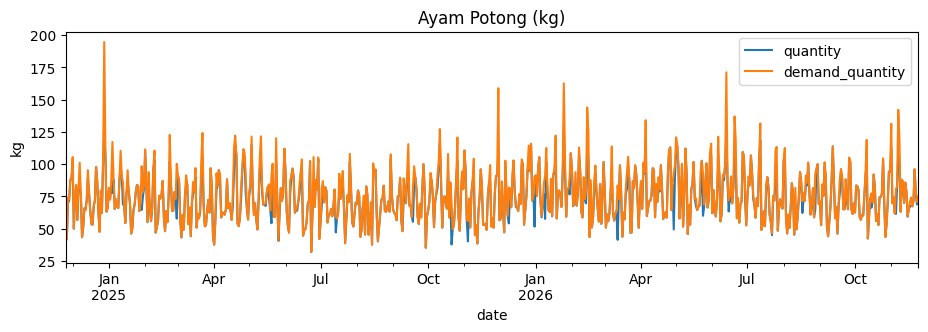

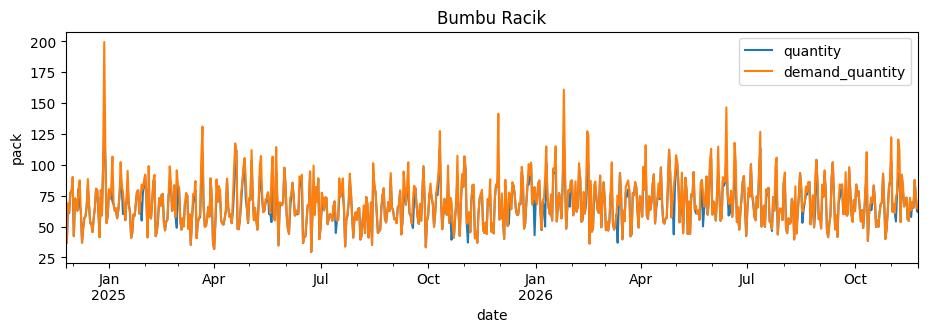

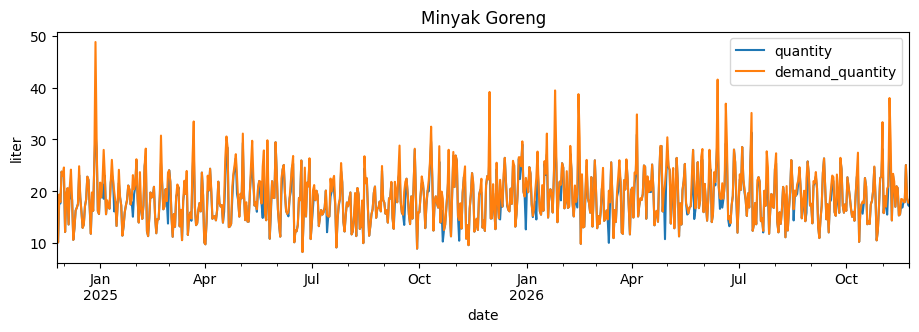

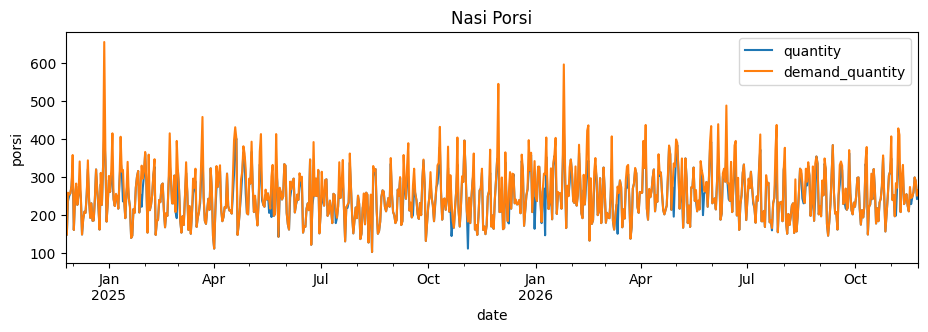

In [5]:
import sys, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0,str(WORK.resolve()))
import abata_ml as ml
from inventory_backtest import backtest
validation=ml.validate_seed(SEED); print(json.dumps(validation,indent=2))
d=ml.history_read(H,ml.master_read(M)); display(d.groupby(['product_name','unit'])[['quantity','demand_quantity']].agg(['min','mean','max']).round(2))
for product,g in d.groupby('product_name'):
    ax=g.set_index('date')[['quantity','demand_quantity']].plot(figsize=(11,3),title=product); ax.set_ylabel(g.unit.iloc[0]); plt.show()

## 6. Feature engineering dan pembagian waktu
Lag 1–7/14/21/28, rolling mean/std dari `shift(1)`. Kalender target harus diketahui sebelum prediksi. Tiga kandidat fitur dan dua konfigurasi LightGBM. Tiga fold expanding 30 hari dipakai hanya di development. 60 hari sebelum test untuk kalibrasi; 30 hari terakhir untuk evaluasi rolling-origin. Model evaluasi tetap sama selama test; hanya residual dari tanggal sebelumnya yang memperbarui kalibrasi. Model deployment terpisah: fit sebelum 60 hari terakhir, lalu gunakan 60 hari terakhir sebagai residual out-of-sample. Tidak ada klaim bahwa model deployment telah diuji independen.

In [6]:
g=d[d.product_name==d.product_name.iloc[0]]
feat=ml.features(g,'demand_quantity',g.date.min()); display(feat[['date','demand_quantity','lag_1','lag_7','rolling_mean_7','rolling_std_7']].tail(10))
days=pd.date_range(d.date.min(),d.date.max()); print('Development end:',days[-91].date(),'Calibration:',days[-90].date(),days[-31].date(),'Historical test:',days[-30].date(),days[-1].date())

,date,demand_quantity,lag_1,lag_7,rolling_mean_7,rolling_std_7
720,2026-11-15,59.32,78.76,119.74,84.605714,18.086657
721,2026-11-16,65.22,59.32,63.10,75.974286,11.875755
722,2026-11-17,70.96,65.22,88.06,76.277143,11.514243
723,2026-11-18,74.20,70.96,86.90,73.834286,10.353181
724,2026-11-19,67.28,74.20,70.00,72.020000,8.655534
725,2026-11-20,71.36,67.28,85.68,71.631429,8.820808
726,2026-11-21,95.96,71.36,78.76,69.585714,6.327935
727,2026-11-22,77.70,95.96,59.32,72.042857,11.614855
728,2026-11-23,70.58,77.70,65.22,74.668571,10.257523
729,2026-11-24,75.04,70.58,70.96,75.434286,9.614549


Development end: 2026-08-26 Calibration: 2026-08-27 2026-10-25 Historical test: 2026-10-26 2026-11-24


## 7. Training, tuning dan kalibrasi
Jalankan pipeline yang sama dengan backend. Output model native LightGBM TXT dan Joblib; manifest menyimpan fitur, versi, checksum, tanggal fit, dan status. Proses ini melakukan training aktual.

In [7]:
manifest=ml.train(H,M,OUT,SEED)
print('Run ID:',manifest['run_id'],'Jumlah estimator:',len(manifest['models']))
display(pd.DataFrame(manifest['models'])[['product_name','target','quantile','alpha','feature_set','cv_pinball','fit_end']])

Trained Ayam Potong (kg) quantity
Trained Ayam Potong (kg) demand_quantity
Trained Bumbu Racik quantity
Trained Bumbu Racik demand_quantity
Trained Minyak Goreng quantity
Trained Minyak Goreng demand_quantity
Trained Nasi Porsi quantity
Trained Nasi Porsi demand_quantity


Run ID: abata-ml-412860cc62a6cfa0 Jumlah estimator: 20


,product_name,target,quantile,alpha,feature_set,cv_pinball,fit_end
0,Ayam Potong (kg),quantity,q50,0.500000,F3,3.953148,2026-09-25
1,Ayam Potong (kg),quantity,q80,0.800000,F3,2.793523,2026-09-25
2,Ayam Potong (kg),demand_quantity,q50,0.500000,F3,5.466634,2026-09-25
3,Ayam Potong (kg),demand_quantity,qcf,0.700000,F3,5.061957,2026-09-25
4,Ayam Potong (kg),demand_quantity,q80,0.800000,F3,4.379357,2026-09-25
5,Bumbu Racik,quantity,q50,0.500000,F3,3.590586,2026-09-25
6,Bumbu Racik,quantity,q80,0.800000,F3,2.509804,2026-09-25
7,Bumbu Racik,demand_quantity,q50,0.500000,F3,5.025847,2026-09-25
8,Bumbu Racik,demand_quantity,q80,0.800000,F3,4.059933,2026-09-25
9,Bumbu Racik,demand_quantity,qcf,0.909091,F3,2.372326,2026-09-25


## 8. Evaluasi dan baseline
WAPE bukan accuracy. Coverage nominal Q80=80%, tidak dijamin. MAE/RMSE memiliki unit masing-masing produk. Semua angka berasal dari CSV output.

,product_name,target,quantile,alpha,mae,rmse,wape,pinball,coverage
2,Ayam Potong (kg),quantity,q50,0.5000,9.8273,12.1810,0.1293,4.9137,0.4667
9,Ayam Potong (kg),quantity,q80,0.8000,10.9895,14.6149,0.1446,3.2208,0.7333
13,Ayam Potong (kg),demand_quantity,q50,0.5000,13.0913,17.2107,0.1644,6.5457,0.4333
20,Ayam Potong (kg),demand_quantity,qcf,0.7000,12.9841,17.2210,0.1631,6.3577,0.5333
24,Ayam Potong (kg),demand_quantity,q80,0.8000,13.9125,17.9029,0.1747,5.3514,0.6667
28,Bumbu Racik,quantity,q50,0.5000,8.8918,10.9492,0.1275,4.4459,0.3667
35,Bumbu Racik,quantity,q80,0.8000,10.0047,13.2111,0.1435,2.9504,0.7333
39,Bumbu Racik,demand_quantity,q50,0.5000,12.9659,16.2748,0.1768,6.4829,0.3333
46,Bumbu Racik,demand_quantity,q80,0.8000,13.0786,17.0132,0.1783,4.7394,0.7000
50,Bumbu Racik,demand_quantity,qcf,0.9091,19.3959,23.3688,0.2645,3.5388,0.9000


variant                           calibrated  empirical28   final    lag1  \
product_name     target                                                     
Ayam Potong (kg) demand_quantity      13.091       14.173  13.091  18.428   
                 quantity              9.827       12.365   9.827  14.530   
Bumbu Racik      demand_quantity      12.966       13.762  12.966  17.024   
                 quantity              8.892       11.776   8.892  14.346   
Minyak Goreng    demand_quantity       3.531        3.920   3.531   4.928   
                 quantity              2.686        3.324   2.686   4.122   
Nasi Porsi       demand_quantity      44.905       44.683  44.905  55.600   
                 quantity             31.668       36.433  31.668  43.700   

variant                             lag7  median7     raw  
product_name     target                                    
Ayam Potong (kg) demand_quantity  16.633   14.697  12.787  
                 quantity         13.053   13.195   9.749  
Bumbu Racik      demand_quantity  15.964   14.765  12.250  
                 quantity         12.577   12.835   8.807  
Minyak Goreng    demand_quantity   4.560    3.800   3.455  
                 quantity          3.490    3.373   2.655  
Nasi Porsi       demand_quantity  52.400   45.533  42.845  
                 quantity         41.533   39.867  31.001

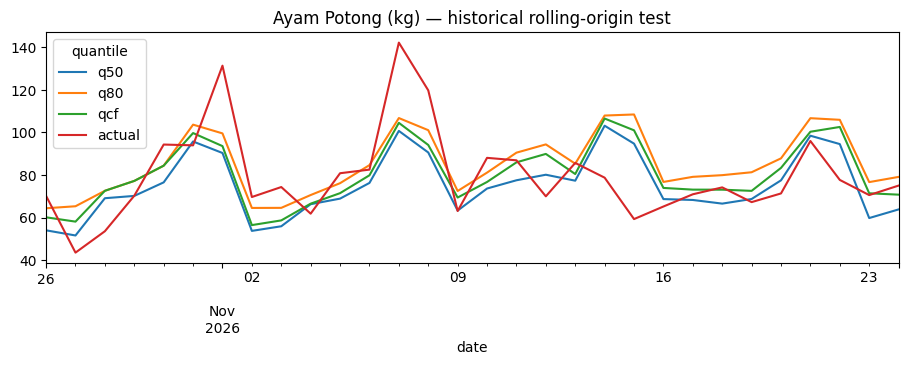

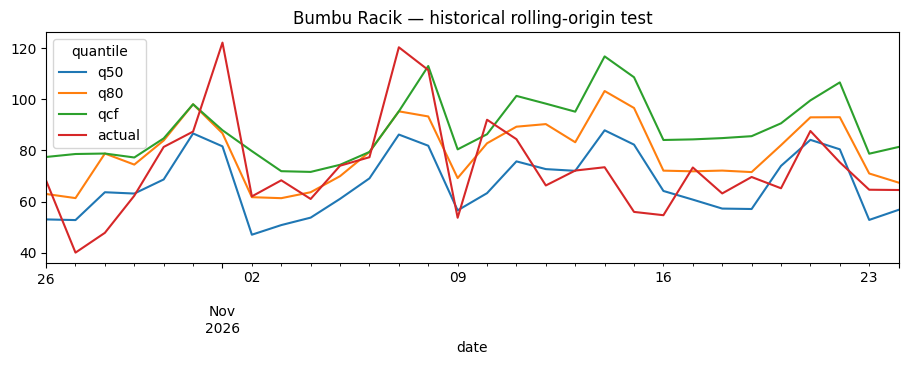

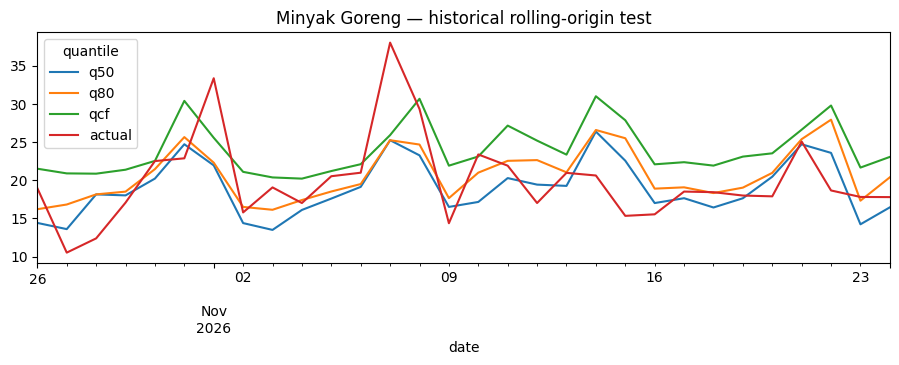

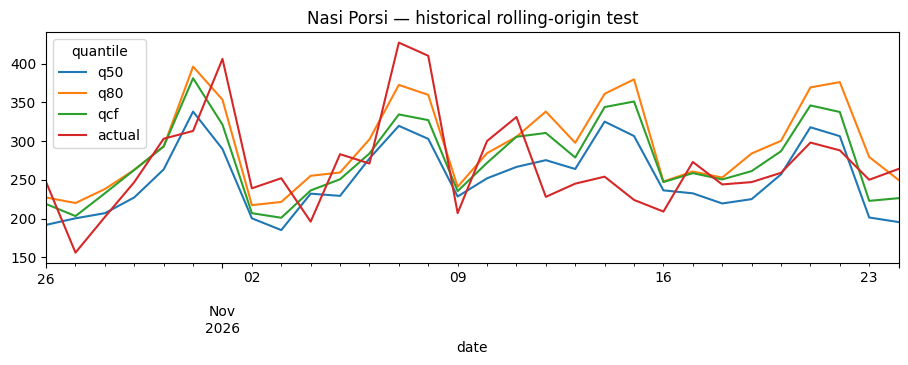

In [8]:
ev=pd.read_csv(OUT/'evaluation.csv'); pred=pd.read_csv(OUT/'test_predictions.csv')
assert len(pred)==600 and not pred.duplicated(['target','product_name','date','quantile']).any()
display(ev[ev.variant.eq('final')][['product_name','target','quantile','alpha','mae','rmse','wape','pinball','coverage']].round(4))
display(ev[ev['quantile'].eq('q50')].pivot(index=['product_name','target'],columns='variant',values='mae').round(3))
for product,g in pred[pred.target.eq('demand_quantity')].groupby('product_name'):
    wide=g.pivot(index='date',columns='quantile',values='prediction'); wide['actual']=g[g['quantile'].eq('q50')].set_index('date').actual
    wide.index=pd.to_datetime(wide.index); wide.plot(figsize=(11,3),title=product+' — historical rolling-origin test'); plt.show()

## 9. Prediksi H+1 load-only
Ubah flag kalender sesuai rencana demo. Nilai nol pada contoh adalah asumsi skenario, bukan klaim bahwa tidak ada libur/promosi aktual. Untuk tanggal setelah H+1, tambah histori harian lengkap terlebih dahulu. Tidak dilakukan fit ulang.

In [9]:
last=d.date.max(); target_date=(last+pd.Timedelta(days=1)).date().isoformat()
# Edit flag sesuai skenario rencana yang diketahui sebelum forecast.
calendar=pd.DataFrame([dict(date=target_date,is_holiday=0,is_promotion=0,is_ramadan=0,is_eid_period=0,data_source=ml.SCOPE)])
calendar.to_csv(WORK/'calendar_demo.csv',index=False)
forecast=ml.predict(H,M,OUT,target_date,WORK/'calendar_demo.csv'); ml.save(OUT/'inference.json',forecast)
display(pd.DataFrame(forecast['predictions']).drop(columns='details').round(3))

,product_name,unit,target,q50,q80,sigma_q50,critical_fractile,empirical_qcf,qcf
0,Ayam Potong (kg),kg,quantity,65.668,78.146,11.302,0.700,82.720,NaN
1,Ayam Potong (kg),kg,demand_quantity,67.268,79.911,14.536,0.700,85.366,76.975
2,Bumbu Racik,pack,quantity,61.848,74.360,10.078,0.909,91.754,NaN
3,Bumbu Racik,pack,demand_quantity,66.948,77.141,13.593,0.909,102.675,87.476
4,Minyak Goreng,liter,quantity,17.382,20.813,2.836,0.930,25.418,NaN
5,Minyak Goreng,liter,demand_quantity,18.586,20.041,3.709,0.930,29.784,22.378
6,Nasi Porsi,porsi,quantity,233.178,264.560,34.149,0.645,264.032,NaN
7,Nasi Porsi,porsi,demand_quantity,248.848,277.956,46.807,0.645,277.194,253.898


## 10. Newsvendor dan restock
Contoh stock = closing historis (diasumsikan layak pakai), inbound/reservasi 0 karena PO historis tidak diketahui. Untuk integrasi, Laravel harus memasok usable on-hand, inbound terkonfirmasi yang tiba tepat waktu, dan reserved. Conservative = Q80 + z80×sigma; bukan optimum klasik. Nasi = produksi, bukan pembelian.

In [10]:
s=d[d.date.eq(last)][['product_name','unit','closing_stock','data_source']].rename(columns={'closing_stock':'usable_on_hand'}).copy(); s['as_of_date']=last.date().isoformat(); s['eligible_inbound']=0; s['reserved']=0
s.to_csv(WORK/'stock_demo.csv',index=False)
recs=ml.recommend(forecast,M,WORK/'stock_demo.csv'); ml.save(OUT/'recommendations.json',recs)
display(pd.DataFrame(recs['recommendations']).round(3))

,product_name,unit,policy,action,target_stock,inventory_position,safety_stock,raw_order,recommended_qty,planned_expenditure_idr,historical_fill_rate
0,Ayam Potong (kg),kg,fixed_q80,purchase_order_draft,79.911,5.442,0.000,74.469,75.0,2625000.0,None
1,Ayam Potong (kg),kg,conservative,purchase_order_draft,92.145,5.442,12.234,86.703,87.0,3045000.0,None
2,Ayam Potong (kg),kg,cost_based,purchase_order_draft,76.975,5.442,0.000,71.533,72.0,2520000.0,None
3,Ayam Potong (kg),kg,empirical28,purchase_order_draft,85.366,5.442,0.000,79.924,80.0,2800000.0,None
4,Bumbu Racik,pack,fixed_q80,purchase_order_draft,77.141,14.283,0.000,62.858,63.0,315000.0,None
5,Bumbu Racik,pack,conservative,purchase_order_draft,88.582,14.283,11.440,74.299,75.0,375000.0,None
6,Bumbu Racik,pack,cost_based,purchase_order_draft,87.476,14.283,0.000,73.193,74.0,370000.0,None
7,Bumbu Racik,pack,empirical28,purchase_order_draft,102.675,14.283,0.000,88.392,89.0,445000.0,None
8,Minyak Goreng,liter,fixed_q80,purchase_order_draft,20.041,5.758,0.000,14.283,16.0,280000.0,None
9,Minyak Goreng,liter,conservative,purchase_order_draft,23.163,5.758,3.121,17.405,18.0,315000.0,None


## 11. Sequential inventory backtesting
Empat kebijakan × 4 bahan × 30 hari = 480 baris. Lead time 1 hari, perfect receipt, FEFO dan expiry, lot awal diasumsikan segar; biaya proxy bukan laba aktual, tidak ada holding cost/terminal valuation. Demand produk dimodelkan independen, bukan joint menu fulfillment.

Perfect H+1 receipts; initial lots assumed fresh; FEFO and expiry; no holding/terminal valuation, capacity or joint-menu fulfillment. Proxy shortage+waste only, expenditure separate. Forecasts use observed historical demand, not simulated fulfilled usage.


,product_name,unit,policy,days,fill_rate,cycle_service,stockout_rate,total_order,shortage,waste,terminal_stock,purchase_expenditure,cost_proxy
0,Ayam Potong (kg),kg,conservative,30,0.978,0.867,0.133,2345.0,53.598,0.0,16.880,82075000.0,1500744.0
1,Ayam Potong (kg),kg,cost_based,30,0.925,0.533,0.467,2203.0,178.718,0.0,0.000,77105000.0,5004104.0
2,Ayam Potong (kg),kg,empirical28,30,0.913,0.667,0.333,2185.0,207.398,0.0,10.680,76475000.0,5807144.0
3,Ayam Potong (kg),kg,fixed_q80,30,0.949,0.700,0.300,2264.0,122.758,0.0,5.040,79240000.0,3437224.0
4,Bumbu Racik,pack,conservative,30,0.979,0.900,0.100,2156.0,46.124,0.0,14.900,10780000.0,299806.0
5,Bumbu Racik,pack,cost_based,30,0.971,0.900,0.100,2142.0,62.824,0.0,17.600,10710000.0,408356.0
6,Bumbu Racik,pack,empirical28,30,0.964,0.867,0.133,2148.0,78.124,0.0,38.900,10740000.0,507806.0
7,Bumbu Racik,pack,fixed_q80,30,0.954,0.700,0.300,2089.0,102.064,0.0,3.840,10445000.0,663416.0
8,Minyak Goreng,liter,conservative,30,0.969,0.900,0.100,582.0,18.532,0.0,6.880,10185000.0,296512.0
9,Minyak Goreng,liter,cost_based,30,0.971,0.933,0.067,582.0,17.217,0.0,5.565,10185000.0,275472.0


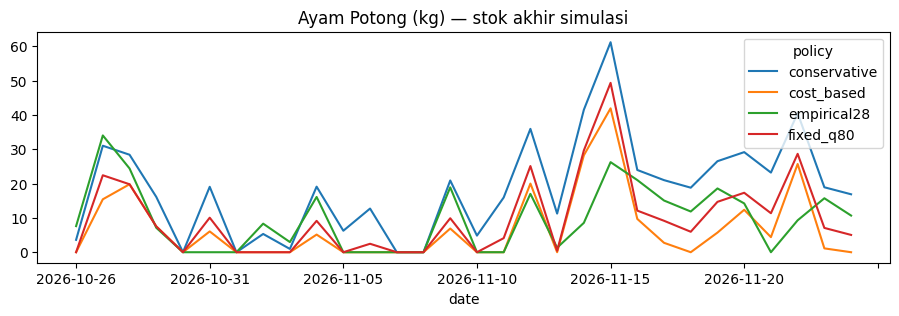

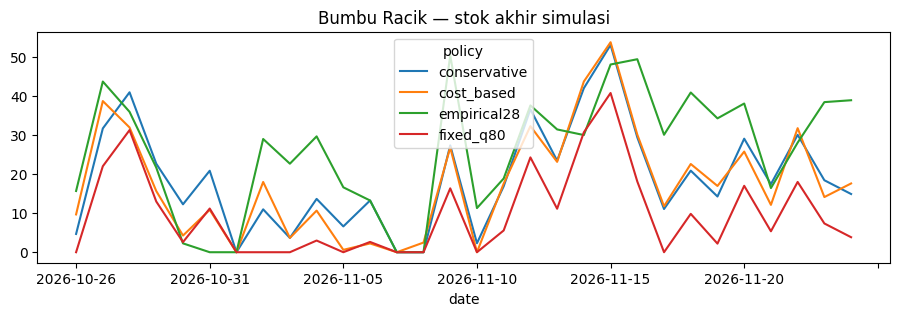

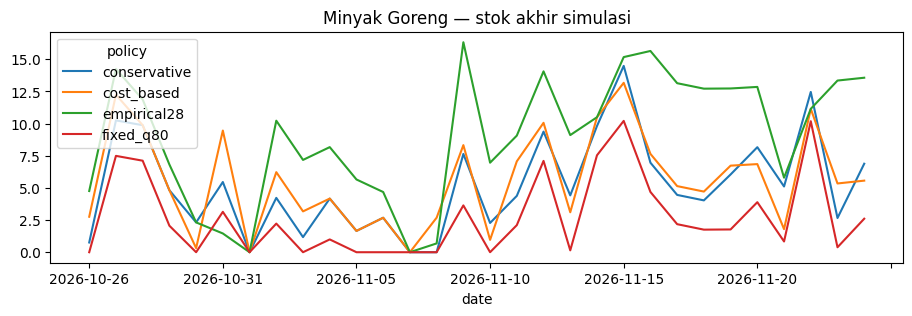

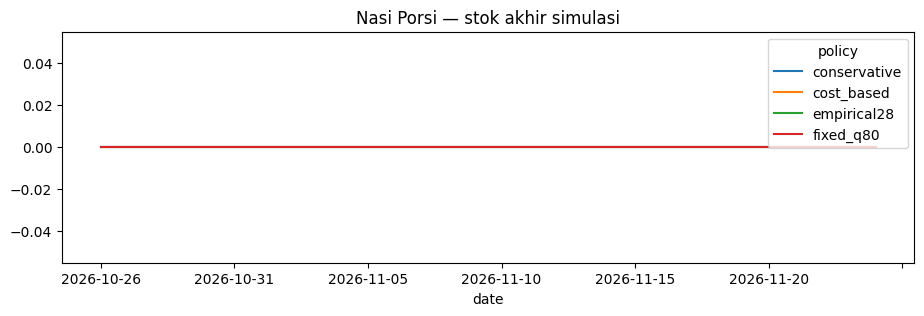

In [11]:
bt=backtest(H,M,OUT/'test_predictions.csv',OUT)
print(bt['assumptions']); display(pd.DataFrame(bt['summary']).round(3))
traj=pd.read_csv(OUT/'sequential_backtest.csv')
assert len(traj)==480 and np.allclose(traj.opening+traj.receipt-traj.fulfilled-traj.waste,traj.closing)
for product,g in traj.groupby('product_name'):
    g.pivot(index='date',columns='policy',values='closing').plot(figsize=(11,3),title=product+' — stok akhir simulasi'); plt.show()

## 12. Download paket integrasi
ZIP berisi model, manifest, source dan artefak evaluasi. OpenCode menggunakan perintah predict/recommend; jangan load pickle dari sumber asing. Model native TXT digunakan oleh CLI.

In [12]:
import shutil
for name in ['abata_ml.py','inventory_backtest.py','calendar_demo.csv','stock_demo.csv']:
    shutil.copy2(WORK/name,OUT/name)
shutil.copy2(M,OUT/'product_master.csv')
(OUT/'requirements.txt').write_text('\n'.join(requirements)+'\n')
archive=shutil.make_archive(str(WORK/'ABATA_ML_COLAB_EXPORT'),'zip',OUT)
print('Export:',archive)
if not os.getenv('ABATA_SEED_DIR'):
    from google.colab import files
    files.download(archive)

Export: /content/abata_colab_work/ABATA_ML_COLAB_EXPORT.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>